# Kling V3 Pro

<p align="center">
  <img src="../../.github/images/banners/fal-kling-v3-pro.png" alt="Kling V3 Pro: one tent, one launch film" width="900" />
</p>

Cinematic text-to-video and image-to-video with multi-shot storyboards, locked characters, and native sound, from Kling through fal on Microsoft Foundry.

| | |
|---|---|
| Released | 2026-11-06 (preview) |
| Publisher | fal (model by Kling) |
| Capability | [Video Generation](../../3-primers/video-generation.md) |
| Model card | [Fal-Kling-V3-Pro](https://ai.azure.com/catalog/models/Fal-Kling-V3-Pro) |
| Announcement | [Release post](https://techcommunity.microsoft.com/blog/azure-ai-foundry-blog/building-the-next-generation-of-multimodal-ai-experiences-with-fal-in-microsoft-/4570032) |
| Docs | [Fal models on Microsoft Foundry](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models) |
| Deployment | US Data Zone, pay-as-you-go |
| Modes | Text-to-video, image-to-video (start and optional end frame), elements, multi-shot |
| Clip shape | 3–15 s · 16:9, 9:16, 1:1 · native audio on by default |
| Rate limit | 2 requests per minute on quota tiers 1–4 |
| Pricing | Not on the model card yet. Check your deployment in the Foundry portal; fal's direct price is on [fal.ai](https://fal.ai/models/fal-ai/kling-video/v3/pro/text-to-video) |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT`, `AZURE_FAL_KLING_V3_PRO_DEPLOYMENT`, `DEMO_MODE` |

**Read first:** the [Video Generation primer](../../3-primers/video-generation.md) explains the terms we use here (image-to-video, first and last frame, elements, multi-shot, native audio, guidance). Ten minutes there makes this notebook much easier.

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Can Kling V3 Pro turn our product launch into a short film, and keep our tent looking like our tent?"*

Contoso Outdoors is relaunching the **TrailMaster X4** tent. Marketing wants a 15-second launch film, cut-downs for every screen, and confidence that the tent, the hiker, and the brand look the same in every shot. We use the [Contoso Outdoors scenario](../../2-scenarios/contoso-retail/) and launch images made by an earlier MAI workshop.

## What We Will Do

- Make clips from text alone, then from our own launch images, with fixed start and end frames
- Tell a three-shot story in one request, and keep the same hiker in every shot with **elements**
- Direct the soundtrack and tune how literally the model follows us
- Measure every clip, and package what we learn for a customer conversation

> Run each cell with **Shift + Enter**. Guess first: before each video, predict one thing it will get right and one it will get wrong.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows clips saved in `examples/` and makes no Azure calls.

**Running it live?** We need four things:

1. **fal enabled on the subscription.** An admin registers the **Fal.EnableDeploy** preview feature ([steps](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models#enable-fal-on-foundry)). It can take 30 minutes.
2. **A Kling V3 Pro deployment** in our Foundry project. Kling uses **US Data Zone**, so the resource must be in a US region ([steps](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models#deploy-fal-models-from-the-foundry-portal)).
3. **A sign-in with a Foundry role** on the resource: run `az login` in a terminal. We use keyless Microsoft Entra ID tokens, never API keys.
4. **`.env` at the repo root** with `MICROSOFT_FOUNDRY_ENDPOINT`, `AZURE_FAL_KLING_V3_PRO_DEPLOYMENT`, and `DEMO_MODE=live`. See [sample.env](../../1-scripts/sample.env).

**Data handling.** fal hosts this model outside Microsoft. Prompts and images we send leave Microsoft, and Microsoft's product terms and DPA don't apply. We only send fictional Contoso data here.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "fal_video.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "").strip()
DEPLOYMENT = os.getenv("AZURE_FAL_KLING_V3_PRO_DEPLOYMENT", "Fal-Kling-V3-Pro").strip()
RPM = int(os.getenv("FAL_REQUESTS_PER_MINUTE", "2"))
PLAY_INLINE = os.getenv("PLAY_INLINE", "true").strip().lower() == "true"

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("MICROSOFT_FOUNDRY_ENDPOINT is missing from .env. Run setup.ipynb, or copy it from the project's Overview page.")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | Deployment: {DEPLOYMENT} | {RPM} requests per minute")

Mode: live | Deployment: Fal-Kling-V3-Pro | 2 requests per minute


The shared helper in [1-scripts/fal_video.py](../../1-scripts/fal_video.py) does the asynchronous work: **submit** the job, **poll** its status, **fetch** the MP4, and save a JSON record of what we asked and what came back. `fal.show()` prints the clip's facts, a strip of frames (which also renders on GitHub), and a player.

In [2]:
sys.path.insert(0, str(ROOT / "1-scripts"))
from fal_video import FalVideo, as_url, scoreboard

HERE = ROOT / "4-models" / "fal-kling-v3-pro"
IMAGES = ROOT / "2-scenarios" / "contoso-retail" / "data" / "generated" / "images"

fal = FalVideo(ENDPOINT, DEPLOYMENT, family="kling/v3/pro", here=HERE, mode=MODE,
               requests_per_minute=RPM, play_inline=PLAY_INLINE, credential=credential)
clips = []

TENT = "the TrailMaster X4, a four-person dome tent with a forest-green body under a burnt-orange rainfly"
print(f"Images from the earlier MAI workshop: {len(list(IMAGES.glob('*.webp')))} in {IMAGES.relative_to(ROOT)}")

Images from the earlier MAI workshop: 12 in 2-scenarios/contoso-retail/data/generated/images


<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. What does Kling make from words alone?

We start with text-to-video: no images, just a shot written the way the primer recommends (subject, action, setting, camera, light, audio). This is our baseline for everything that follows.

> 🔮 **Guess first:** will the tent's colors match our description? Will the rain *sound* like rain on fabric?

   Reusing 01-text-to-video from output/ (same request).
01-text-to-video: 1920x1080 | 5.0 s | 24 fps | audio | made in 179 s | (yours)


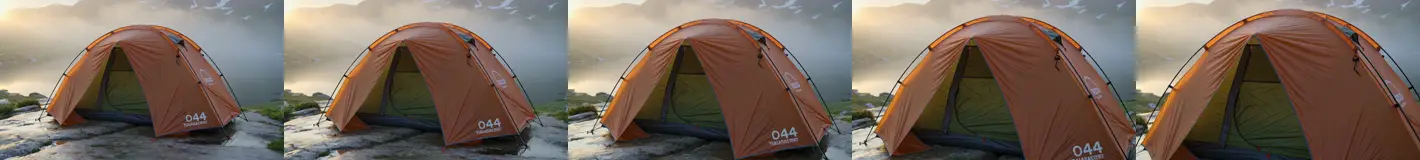

   19.93 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/01-text-to-video.mp4


In [3]:
RAIN_SHOT = f"""Medium shot of {TENT}, pitched on a granite ledge above a misty alpine lake at sunrise.
Rain starts; drops bead and run off the rainfly while the tent stays taut.
Slow dolly in toward the closed door. Soft golden light, light mist.
Audio: steady rain on tent fabric, distant birds, no music."""

text_clip = fal.run("01-text-to-video", "text-to-video", prompt=RAIN_SHOT, duration="5", aspect_ratio="16:9")
clips.append(text_clip)
fal.show(text_clip)

**What to look for:** the rainfly color and shape (does it look like *a* tent or *our* tent?), whether the dolly-in actually happens, rain that runs *down* the fabric, and a soundtrack that matches what we see. Text-to-video invents the product; the next sections give the model our real one.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Can it animate our launch image without changing the product?

Image-to-video starts from a picture we own. Here that's the lifestyle photo from the earlier workshop, with all five products in one scene. The prompt now describes **motion only**: the image already defines what everything looks like.

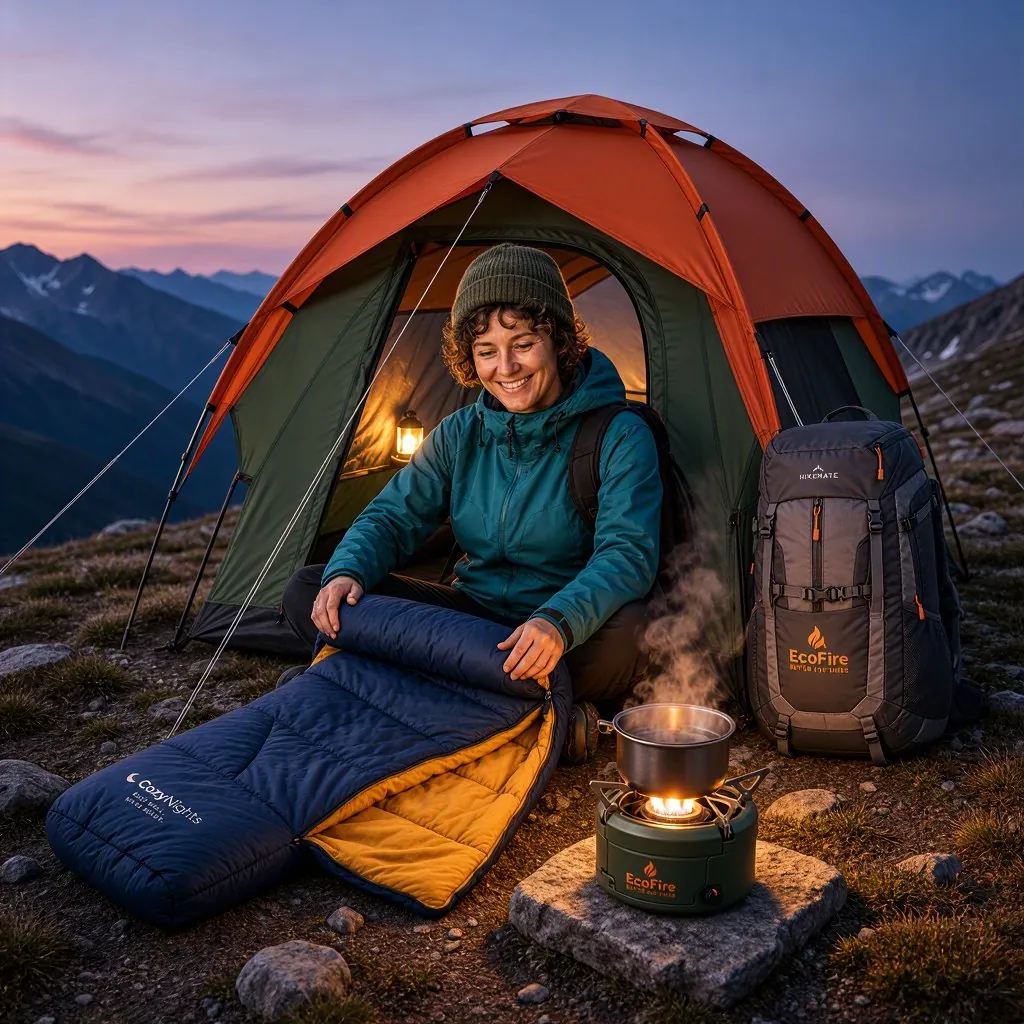

   Reusing 02-image-to-video from output/ (same request).
02-image-to-video: 1440x1440 | 5.0 s | 24 fps | audio | made in 205 s | (yours)


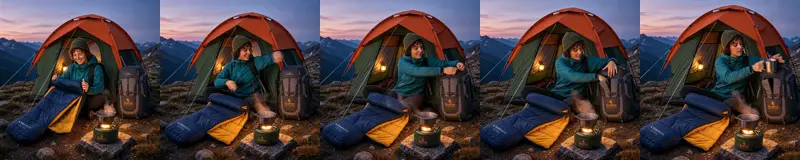

   21.96 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/02-image-to-video.mp4


In [4]:
from IPython.display import Image as Picture, display

display(Picture(filename=str(IMAGES / "lifestyle-all-products.webp"), width=360))

ANIMATE = """The hiker unzips the backpack and pulls out a mug, steam rising from the stove beside the tent.
A light breeze moves the tent fabric. Camera holds still, then slowly pushes in.
Audio: crackle of the stove, wind in the trees, a zipper."""

image_clip = fal.run("02-image-to-video", "image-to-video", prompt=ANIMATE, duration="5",
                     start_image_url=as_url(IMAGES / "lifestyle-all-products.webp"))
clips.append(image_clip)
fal.show(image_clip)

**What to look for:** compare frame 1 with the source image (it should match closely), then watch the products over time. Do logos, zip pulls, and colors hold, or drift by the last frame? Image-to-video locks the *start*; consistency after that is the model's job.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. Can we control where the clip starts *and* where it ends?

With a start **and** an end image, the model invents only the motion between them. Our pair: the lakeside campsite before and after a round of edits that changed the tent's color. That makes a "new colorway" reveal.

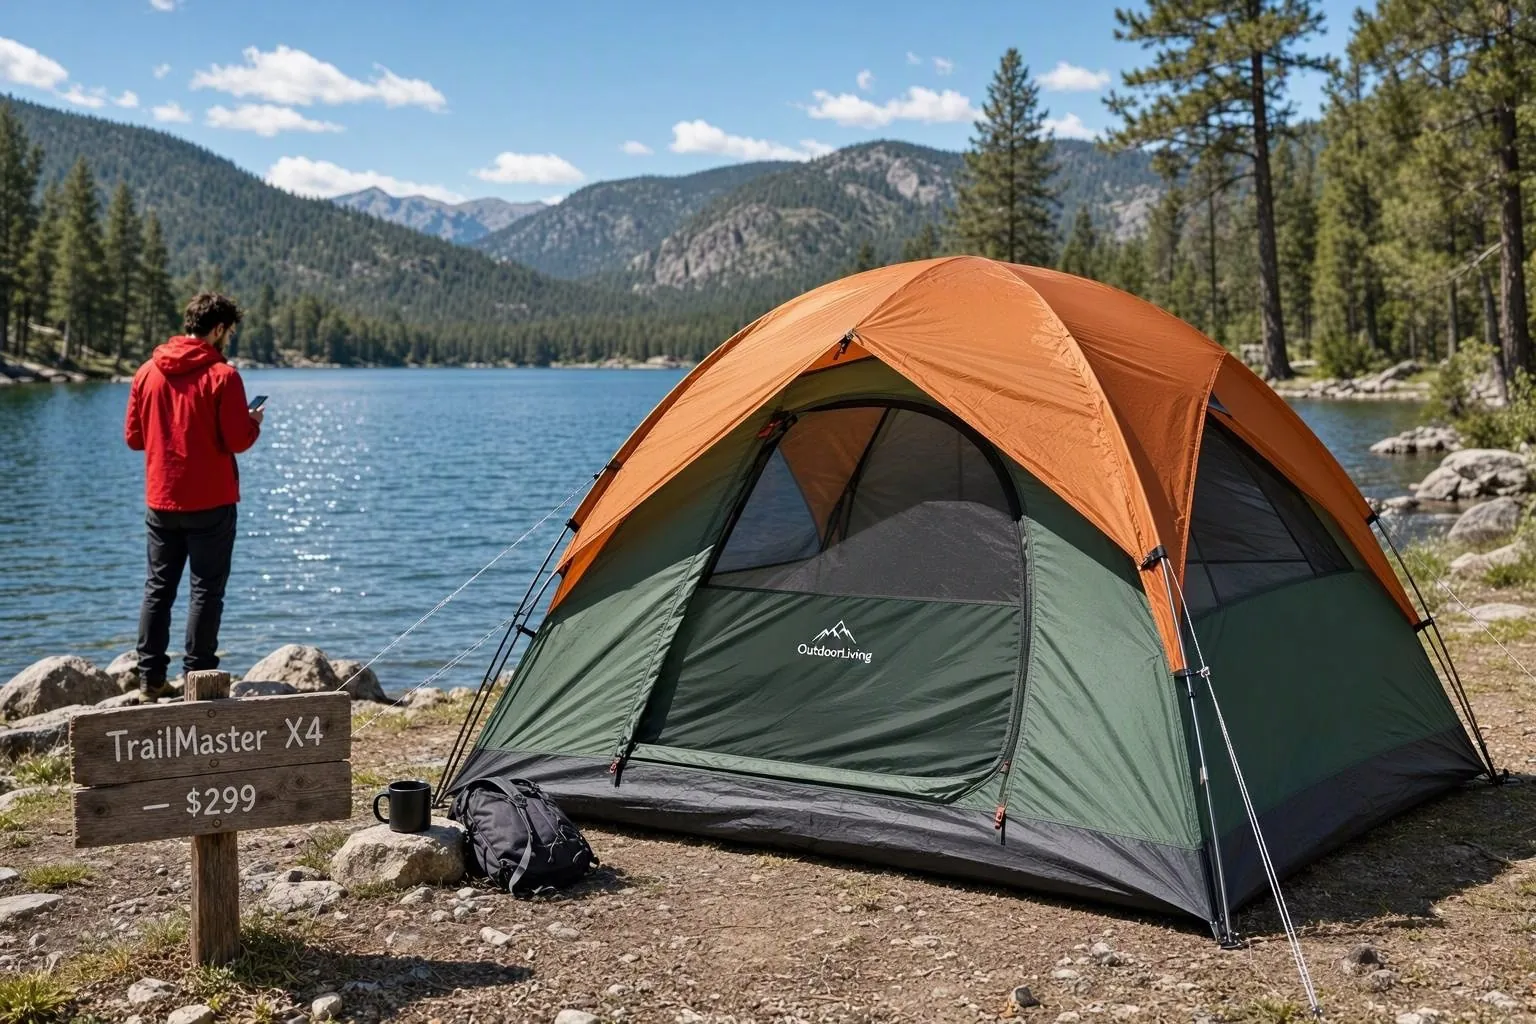

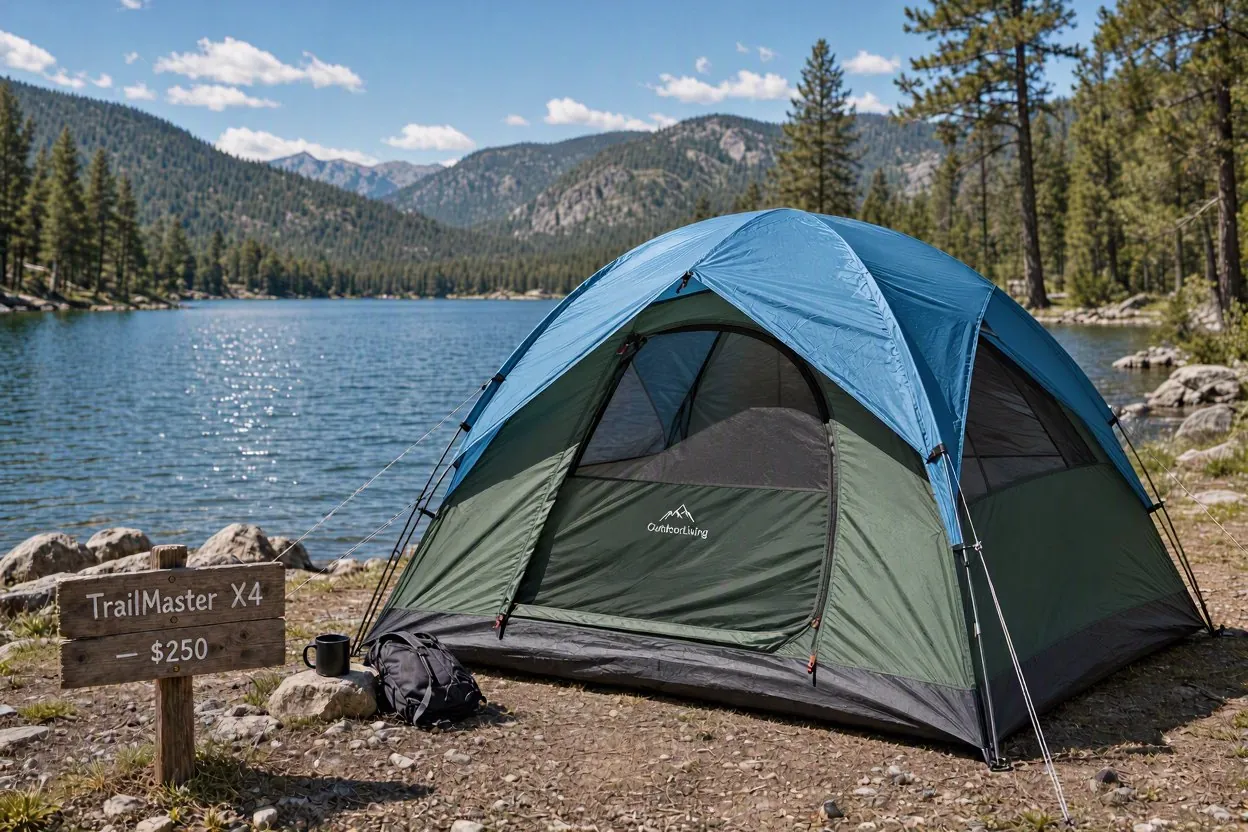

   Reusing 03-first-and-last-frame from output/ (same request).
03-first-and-last-frame: 1764x1176 | 5.0 s | 24 fps | audio | made in 256 s | (yours)


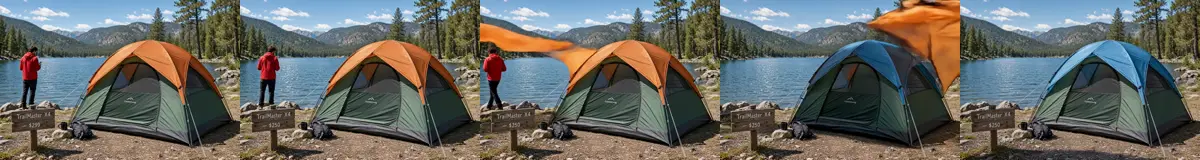

   16.29 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/03-first-and-last-frame.mp4


In [5]:
display(Picture(filename=str(IMAGES / "campsite-before.webp"), width=360), Picture(filename=str(IMAGES / "campsite-after.webp"), width=360))

REVEAL = """A gust of wind ripples across the lake; as it passes the tent, its rainfly changes to the new color.
Everything else stays the same. Static camera. Audio: wind gust, water lapping."""

keyframe_clip = fal.run("03-first-and-last-frame", "image-to-video", prompt=REVEAL, duration="5",
                        start_image_url=as_url(IMAGES / "campsite-before.webp"),
                        end_image_url=as_url(IMAGES / "campsite-after.webp"))
clips.append(keyframe_clip)
fal.show(keyframe_clip)

**What to look for:** the first and last frames should match the two images. In between, check what *shouldn't* change: the lake, trees, and shadows. The two images have different sizes (1536×1024 and 1248×832); notice how the model handles the framing.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Can one request tell a three-shot story?

Kling can cut. With `multi_prompt` we write each shot and its length ourselves (`shot_type="customize"`). With `shot_type="intelligent"` we write one prompt and let the model decide where to cut. Same story, both ways.

> 🔮 **Guess first:** which version will have cleaner cuts? Which will follow our story beats more closely?

   Submitted 04-multi-shot-customize (d535eccc...)............................................................. done in 353 s
   Submitted 04-multi-shot-intelligent (dccf2dcb...)............................................................. done in 352 s
04-multi-shot-customize: 1920x1080 | 12.1 s | 24 fps | audio | made in 353 s | (yours)


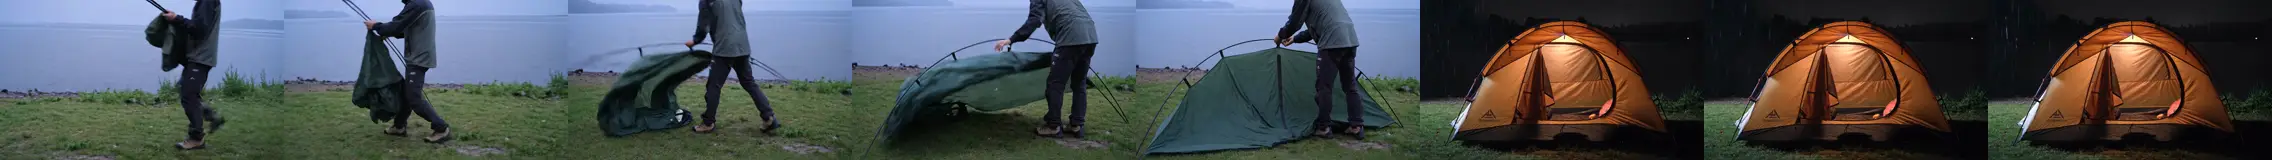

   41.76 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/04-multi-shot-customize.mp4
04-multi-shot-intelligent: 1920x1080 | 12.1 s | 24 fps | audio | made in 352 s | (yours)


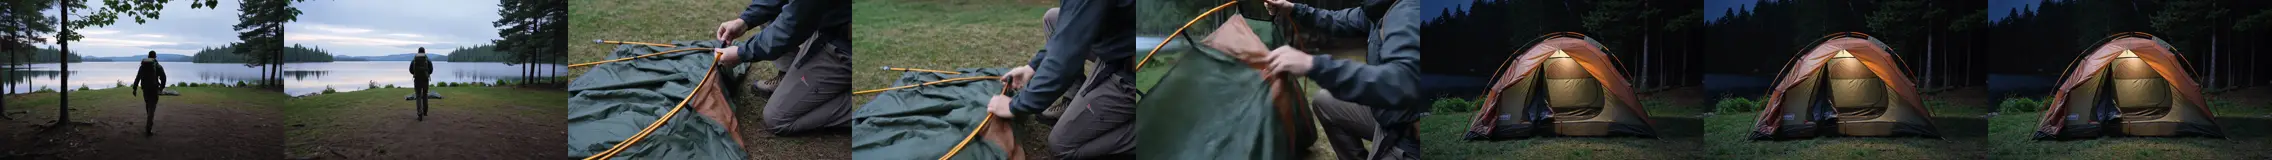

   41.71 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/04-multi-shot-intelligent.mp4


In [7]:
STORY = f"""A hiker arrives at a lakeside clearing at dusk with {TENT}, pitches it in seconds,
and by night it glows warm from inside while rain falls. Audio: footsteps, pole clicks, rain on fabric."""

SHOTS = [
    {"prompt": f"Wide shot: a hiker reaches a lakeside clearing at dusk carrying {TENT} in its bag. Audio: footsteps on gravel.", "duration": "4"},
    {"prompt": "Close-up: hands snap the aluminum poles together and the tent rises in seconds. Audio: pole clicks, fabric rustle.", "duration": "4"},
    {"prompt": "Wide shot: night, rain falls, the tent glows warm from inside on the shore. Audio: rain on fabric, soft wind.", "duration": "4"},
]
# The Foundry route rejects multi_prompt without a top-level prompt (422 "body.prompt: Field required").
storyboard_clip = fal.run("04-multi-shot-customize", "text-to-video", prompt=STORY, multi_prompt=SHOTS, shot_type="customize",
                          duration="12", aspect_ratio="16:9")

intelligent_clip = fal.run("04-multi-shot-intelligent", "text-to-video", prompt=STORY, shot_type="intelligent",
                           duration="12", aspect_ratio="16:9")
clips += [storyboard_clip, intelligent_clip]
fal.show(storyboard_clip, intelligent_clip, frames=8)

**What to look for:** count the cuts in each strip. With `customize`, cuts should land near 4 s and 8 s. Then check continuity *across* cuts: is it the same tent and the same hiker in every shot? This is the main thing that sets multi-shot apart from stitching three separate clips together.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 5. Can the same hiker appear in every shot?

**Elements** lock a subject from a front view plus extra reference images. The prompt refers to them as `@Element1`, `@Element2`. We lock the hiker and the tent from the workshop's product images, and start from the campsite photo. Elements are an image-to-video feature.

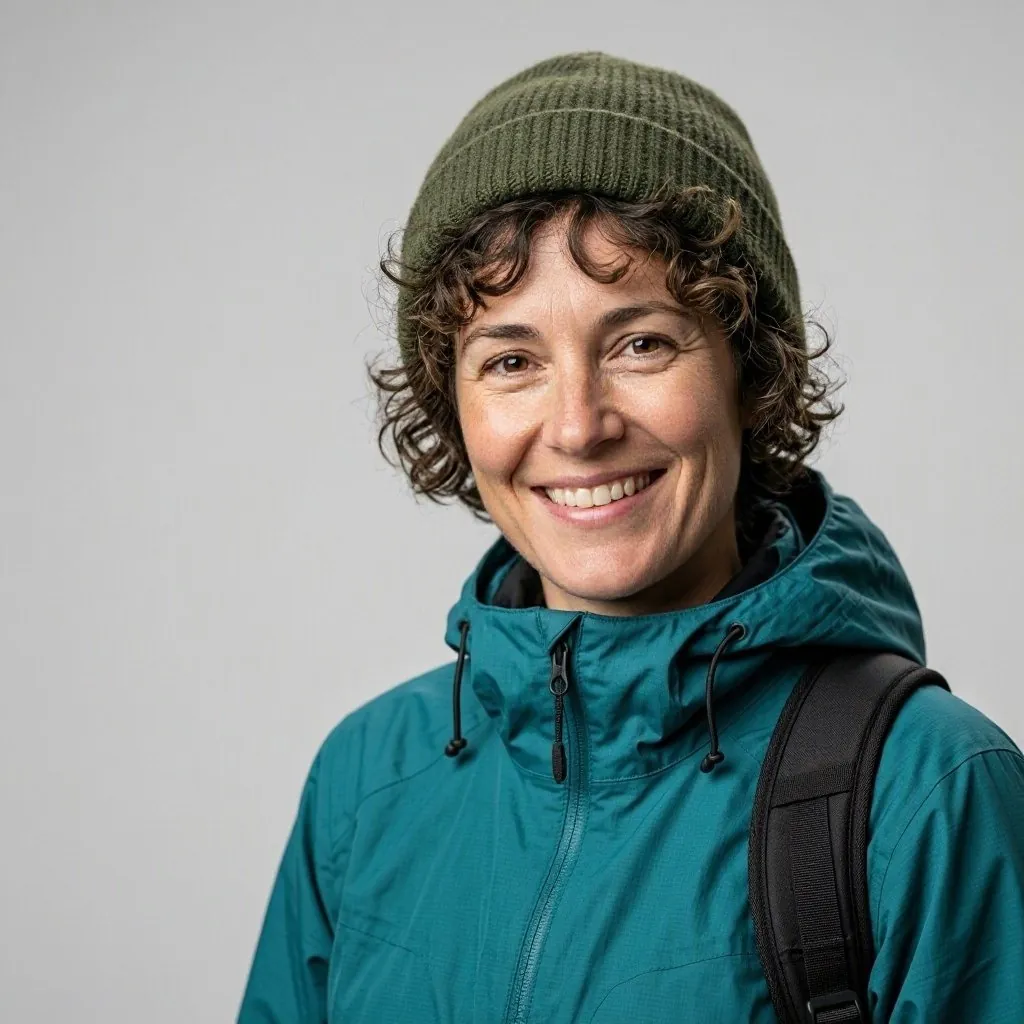

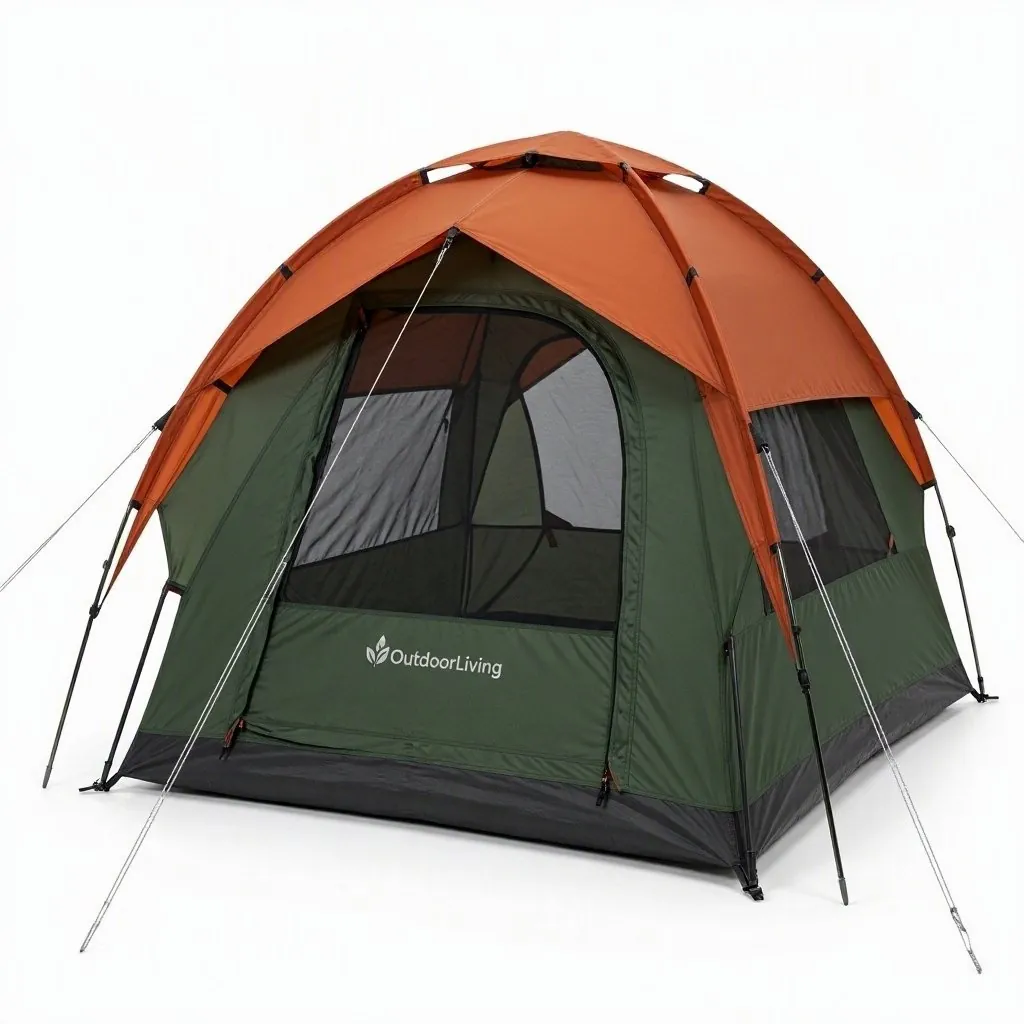

   Submitted 05-elements (1ddf31ea...)............................... done in 179 s
05-elements: 1764x1176 | 6.0 s | 24 fps | audio | made in 179 s | (yours)


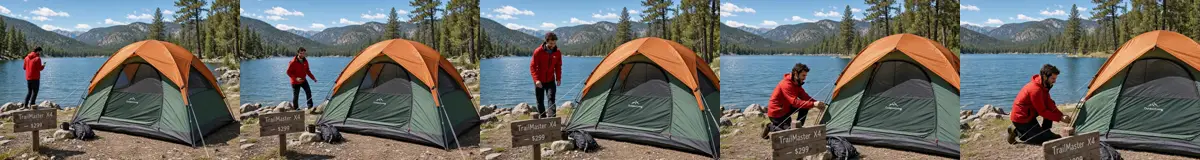

   25.07 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/05-elements.mp4


In [8]:
display(Picture(filename=str(IMAGES / "prop-hiker.webp"), width=200), Picture(filename=str(IMAGES / "prop-tent.webp"), width=200))

ELEMENTS = [
    {"frontal_image_url": as_url(IMAGES / "prop-hiker.webp"), "reference_image_urls": [as_url(IMAGES / "lifestyle-all-products.webp")]},
    {"frontal_image_url": as_url(IMAGES / "prop-tent.webp"), "reference_image_urls": [as_url(IMAGES / "campsite-before.webp")]},
]
LOCKED = """@Element1 walks into frame, kneels beside @Element2, and tightens a guy line, then looks out at the lake and smiles.
Camera tracks right with the hiker. Audio: footsteps on grass, the guy line creaking."""

element_clip = fal.run("05-elements", "image-to-video", prompt=LOCKED, duration="6", elements=ELEMENTS,
                       start_image_url=as_url(IMAGES / "campsite-before.webp"))
clips.append(element_clip)
fal.show(element_clip)

**What to look for:** compare the hiker's jacket, hair, and pack with `prop-hiker.webp`. A locked element should still be recognizable at the end of the clip. Elements need images of at least 300 px; we pass extra angles through `reference_image_urls`. Our workshop only has one angle of each, so we use a scene image as the second view. More real angles work better.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 6. Does the soundtrack match the scene, and can we turn it off?

Native audio is on by default. Kling can also speak: we put dialogue in quotes and, as the API docs ask, write English speech in lowercase (proper nouns capitalized). Then we turn audio off for a clip that will get its own soundtrack.

   Submitted 06-dialogue (748aa22f...)............................ done in 163 s
   Submitted 06-no-audio (7b776337...).............................. done in 174 s
06-dialogue: 1920x1080 | 5.0 s | 24 fps | audio | made in 162 s | (yours)


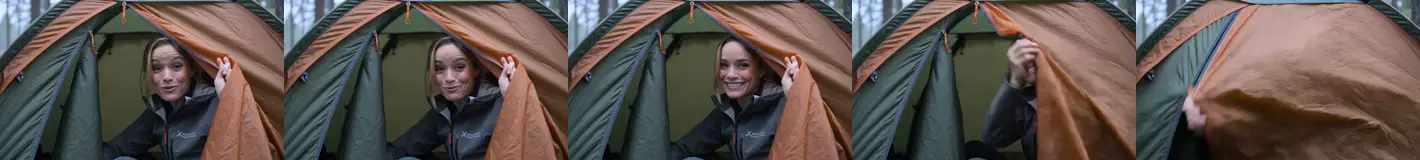

   17.94 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/06-dialogue.mp4
06-no-audio: 1920x1080 | 5.0 s | 24 fps | no audio | made in 174 s | (yours)


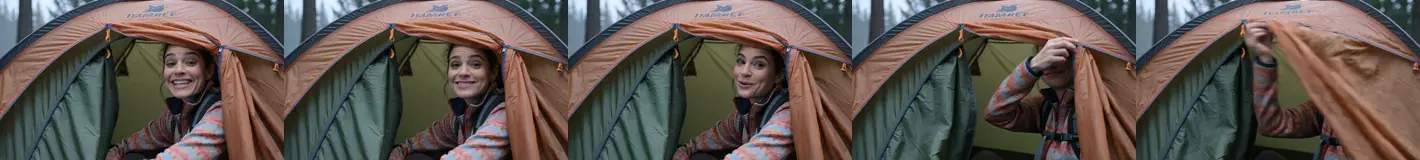

   19.03 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/06-no-audio.mp4


In [9]:
SPOKEN = f"""Close-up of a smiling hiker sitting in the open door of {TENT} as rain falls outside.
She says: "rain in the forecast? we're staying out." Then she zips the door closed.
Audio: rain on fabric, her voice close and warm, the zipper."""

voice_clip = fal.run("06-dialogue", "text-to-video", prompt=SPOKEN, duration="5", generate_audio=True)
silent_clip = fal.run("06-no-audio", "text-to-video", prompt=SPOKEN, duration="5", generate_audio=False)
clips += [voice_clip, silent_clip]
fal.show(voice_clip, silent_clip)

**What to look for:** lip sync on the spoken line, the zipper sound landing when the zipper moves, and `no audio` on the silent clip's facts line. Speech is generated in Chinese or English; other languages are translated to English, so localized voiceovers need another route.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 7. How literally should the model follow us?

`cfg_scale` (0 to 1, default 0.5) sets how strictly Kling follows the prompt; `negative_prompt` lists what to avoid. We render the same detailed shot at a low and a high guidance value.

   Submitted 07-cfg-0.2 (dad5fe28...)............................................. done in 269 s
   Submitted 07-cfg-0.9 (a63c8a94...).......................... done in 151 s
07-cfg-0.2: 1920x1080 | 5.0 s | 24 fps | audio | made in 269 s | (yours)


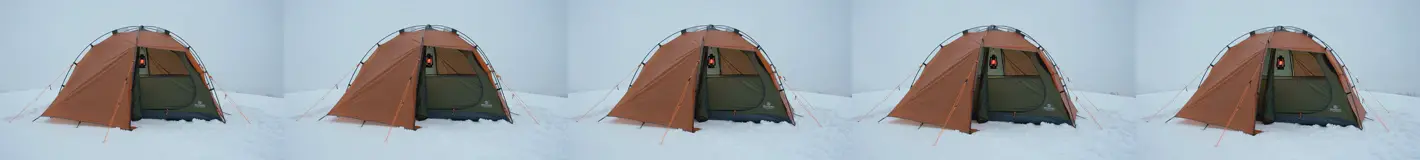

   14.24 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/07-cfg-0.2.mp4
07-cfg-0.9: 1920x1080 | 5.0 s | 24 fps | audio | made in 151 s | (yours)


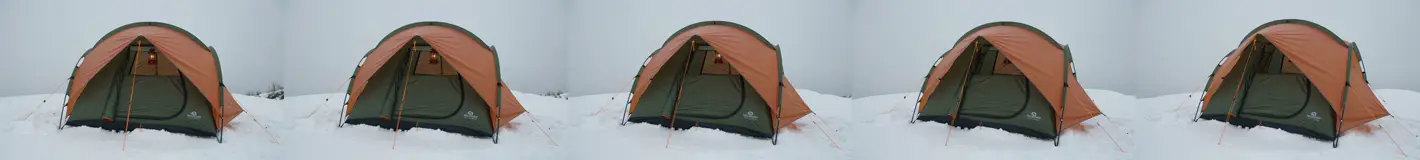

   13.59 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/07-cfg-0.9.mp4


In [10]:
DETAILED = f"""{TENT} stands alone on a snowy ridge. Exactly three orange guy lines, a small silver logo on the door,
and a red lantern hanging inside. Slow orbit around the tent. Audio: wind only."""

loose_clip = fal.run("07-cfg-0.2", "text-to-video", prompt=DETAILED, duration="5", cfg_scale=0.2)
strict_clip = fal.run("07-cfg-0.9", "text-to-video", prompt=DETAILED, duration="5", cfg_scale=0.9,
                      negative_prompt="blur, distorted text, extra tents, people")
clips += [loose_clip, strict_clip]
fal.show(loose_clip, strict_clip)

**What to look for:** count the details we asked for (three guy lines, the logo, the red lantern) in each clip. Higher guidance usually hits more of them but can look stiffer. Lower guidance looks more natural but drifts from the brief. Neither value is "right"; it depends on the job.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 8. Can one brief cover every screen?

Kling's text-to-video offers `16:9`, `9:16`, and `1:1`. We already have 16:9 from section 1; now the same shot for a phone story and a feed post.

   Submitted 08-aspect-9x16 (cc4b3685...)........................... done in 160 s
   Submitted 08-aspect-1x1 (cd54a59a...).................................. done in 197 s
08-aspect-9x16: 1080x1920 | 5.0 s | 24 fps | audio | made in 160 s | (yours)


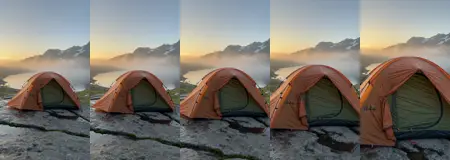

   17.53 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/08-aspect-9x16.mp4
08-aspect-1x1: 1440x1440 | 5.0 s | 24 fps | audio | made in 197 s | (yours)


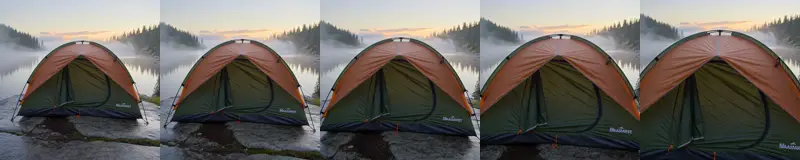

   16.04 MB is too big to embed. Open it here: /workspaces/model-releases/4-models/fal-kling-v3-pro/output/08-aspect-1x1.mp4


In [11]:
vertical_clip = fal.run("08-aspect-9x16", "text-to-video", prompt=RAIN_SHOT, duration="5", aspect_ratio="9:16")
square_clip = fal.run("08-aspect-1x1", "text-to-video", prompt=RAIN_SHOT, duration="5", aspect_ratio="1:1")
clips += [vertical_clip, square_clip]
fal.show(vertical_clip, square_clip)

**What to look for:** does the model *recompose* for each frame (the tent centered and taller in 9:16) or simply crop? Each clip is a new generation, so the tent itself can change between formats. For strict consistency across formats, start each one from the same image instead.

### 🔧 Break it on purpose

Kling accepts 3 to 15 seconds. What happens if we ask for 16? Reading this error is faster than reading the docs.

In [12]:
if MODE == "live":
    try:
        fal.run("break-16-seconds", "text-to-video", prompt=RAIN_SHOT, duration="16")
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 422 and names `duration`, listing the allowed values '3' to '15'.")

400 while submitting on Fal-Kling-V3-Pro. The service rejected a setting. The message below names it; compare it with the model's limits in the At a glance table.
{"detail": "[{\"type\":\"enum\",\"loc\":[\"duration\"],\"msg\":\"Input should be '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14' or '15'\",\"input\":\"16\",\"ctx\":{\"expected\":\"'3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14' or '15'\"},\"url\":\"https://errors.pydantic.dev/2.14/v/enum\"}]", "error_type": "schema_validation_error"}


The service rejects the request **before** queueing it, so nothing is billed. Note that `duration` is a **string** for Kling (`"5"`, not `5`). Sending a number is another quick way to get a validation error.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 9. What did each clip cost us in time?

### Scoreboard

Every clip we made, from its saved record: how long the job took end to end, the duration we asked for vs the one we got, and the output's shape and size.

In [13]:
scoreboard(clips)

clip                                made in  asked    got       size   fps     MB audio
01-text-to-video                    178.9 s      5   5.04  1920x1080  24.0  19.93 yes
02-image-to-video                   205.0 s      5   5.04  1440x1440  24.0  21.96 yes
03-first-and-last-frame             256.4 s      5   5.04  1764x1176  24.0  16.29 yes
04-multi-shot-customize             353.0 s     12  12.05  1920x1080  24.0  41.76 yes
04-multi-shot-intelligent           352.2 s     12  12.05  1920x1080  24.0  41.71 yes
05-elements                         178.8 s      6   6.04  1764x1176  24.0  25.07 yes
06-dialogue                         162.5 s      5   5.04  1920x1080  24.0  17.94 yes
06-no-audio                         173.7 s      5   5.04  1920x1080  24.0  19.03 no
07-cfg-0.2                          268.6 s      5   5.04  1920x1080  24.0  14.24 yes
07-cfg-0.9                          151.1 s      5   5.04  1920x1080  24.0  13.59 yes
08-aspect-9x16                      160.0 s      5   

**What to look for:** how much longer the 12-second multi-shot clips take than 5-second clips, and whether delivered durations match what we asked for. With a 2-requests-per-minute limit, a 10-clip campaign takes at least 5 minutes of submits plus render time. For pricing, use the deployment's page in the Foundry portal, not estimates.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Teach it to a customer

### What it does, and why it matters

- **Cinematic text-to-video and image-to-video, 3–15 s**, with native sound and dialogue.
- **Multi-shot in one request**: write the shots or let the model cut, and the subject stays consistent across cuts.
- **Elements** lock a character or product from reference images: the same hiker in every shot.
- **Start and end frames** let a brand control the opening and closing image exactly.

### A prompt recipe that works

`[shot size] of [subject with fixed details], [one action with a start and end], [setting, time, weather]. [Camera move]. [Light and style]. Audio: [ambience], [effects], "[dialogue in lowercase]".`

For image-to-video, describe **motion only**; the image already defines the look.

### Honest answers to common questions

- **Is it production-ready?** It's in public preview on Foundry. Validate quality and terms before production.
- **Where does our data go?** To fal, outside Microsoft. Microsoft's product terms, DPA, and certifications don't apply. Review [fal's terms](https://fal.ai/legal) with the customer.
- **Where can it run?** Kling is offered with **US Data Zone** deployments only.
- **How fast can we scale?** Quota tiers 1–4 allow 2 requests per minute; tiers 5–7 allow 40.
- **Which languages can it speak?** Chinese and English; other languages are translated to English.

### When something goes wrong

- **403 on the first call** → Fal.EnableDeploy isn't registered yet, or our sign-in lacks a Foundry role → register the feature and wait up to 30 minutes, or ask for the role.
- **404** → the deployment name in `.env` doesn't match the portal, or the region isn't a US Data Zone region → copy the exact name from **Deployments**.
- **422 on `duration`** → a number instead of a string, or outside 3–15 → send `"5"`.
- **The product drifts by the last frame** → start from an image (image-to-video) and lock the product as an element.
- **Cuts land in odd places** → switch from `intelligent` to `customize` and set each shot's duration.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Four seasons, four shots.** Use [four-seasons.webp](../../2-scenarios/contoso-retail/data/generated/images/four-seasons.webp) as the start image and write a four-shot `multi_prompt` that moves through the seasons.
- **Two characters.** Add a second person as `@Element3` and give each one a line of dialogue. Do their voices stay distinct?
- **The poster comes alive.** Animate [launch-poster.webp](../../2-scenarios/contoso-retail/data/generated/images/launch-poster.webp). Does "HOME, ANYWHERE." stay readable for the whole clip?

In [ ]:
# Your experiment here. Try: fal.run("my-clip", "text-to-video", prompt="...", duration="5")

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Made clips from text alone, then from our own launch images, with fixed start and end frames
- ✅ Told a three-shot story in one request and kept the same hiker in every shot with elements
- ✅ Directed the soundtrack, turned it off, and tuned how literally the model follows us
- ✅ Measured every clip and packaged the findings for a customer conversation

➡️ **Next:** compare with [MiniMax H3 Max](../fal-minimax-h3-max/), which takes up to 12 references (images, video, and audio) in one request.

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Fal models on Microsoft Foundry](https://learn.microsoft.com/azure/foundry/how-to/fal-ai-models/enable-fal-models) · [Video Generation primer](../../3-primers/video-generation.md) · [Kling V3 Pro API on fal](https://fal.ai/models/fal-ai/kling-video/v3/pro/image-to-video/api)